# €STR curve construction

The aim of this notebook is to build the euro **€STR (OIS) discount curve** from public data, step by step, before
gathering the code in a class (`EstrCurveBuilder`, Section 8).

**Pipeline :**
1. Load the €STR fixings, the ECB key rates and meeting calendar, the AAA government curve (`Data/EUR`, downloaded by
   `python Data/EUR/download_data.py`).
2. Reproduce the ECB compounded €STR index from the daily fixings (conventions check).
3. Define dated €STR OIS instruments (T+2 spot, annual ACT/360, 1-day payment lag, TARGET calendar).
4. Get OIS quotes: a hand-filled file `Data/EUR/ESTR_OIS_Quotes_YYYYMMDD.csv` if available, otherwise **proxy**
   quotes built from the AAA government curve.
5. Bootstrap the curve with several interpolations, then build the market-standard short end: **step forwards between
   ECB meeting effective dates**, and read the implied policy path.
6. Risk: par-point sensitivities by re-bootstrapping.

> **Real vs proxy.** €STR fixings, key rates, meeting dates and the AAA curve are official ECB data. €STR OIS quotes are
> not free (Data/EUR/README.md): until a quote file is filled, every curve below is built on **proxy quotes**, and the
> numbers (implied hikes, swap rates) describe the AAA curve more than the OIS market. The construction code is the same
> for real quotes.

Single curve: since the €STR is the collateral rate of cleared swaps, the same curve discounts and projects €STR flows.

In [1]:
import os, sys, glob
sys.path.append(os.path.abspath(".."))                       # Projets : Fixed_Income_Models package

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from scipy.optimize import least_squares, brentq

from Fixed_Income_Models import YieldCurve, Bootstrapper, Instrument

pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.prop_cycle": cycler(color=COLORS), "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "lines.linewidth": 2, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "axes.titlesize": 11, "axes.titleweight": "bold"})

DATA = os.path.join("..", "Data", "EUR")
read = lambda name: pd.read_csv(os.path.join(DATA, name), parse_dates=["Date"], index_col="Date")
fixings, compounded, key_rates, aaa = (read("ESTR_Fixings.csv"), read("ESTR_Compounded_Index.csv"),
                                       read("ECB_KeyRates.csv"), read("ECB_AAA_YieldCurve.csv"))
meetings = pd.read_csv(os.path.join(DATA, "ECB_Meetings.csv"), parse_dates=["Decision", "Effective"])
HOLIDAYS = pd.to_datetime(pd.read_csv(os.path.join(DATA, "TARGET_Holidays.csv"))["Date"]).values.astype("datetime64[D]")
estr = fixings["ESTR"] / 100
VALUATION = aaa.index[-1]                                    # last date with both the AAA curve and a ESTR fixing
print(f"Valuation date {VALUATION.date()} | ESTR {100 * estr.loc[VALUATION]:.3f}% | "
      f"DFR {key_rates['DFR'].loc[VALUATION]:.2f}% | last fixing {estr.index[-1].date()}")

Valuation date 2026-10-05 | ESTR 2.438% | DFR 2.50% | last fixing 2026-10-06


## 1. Data and conventions

### 1.1 €STR and the ECB corridor
The €STR is the volume-weighted trimmed mean of unsecured overnight borrowing by euro area banks, published by the ECB
each TARGET business day at 08:00 for the previous business day. With abundant excess liquidity it trades a few basis
points **below the deposit facility rate** (DFR), the floor of the corridor.

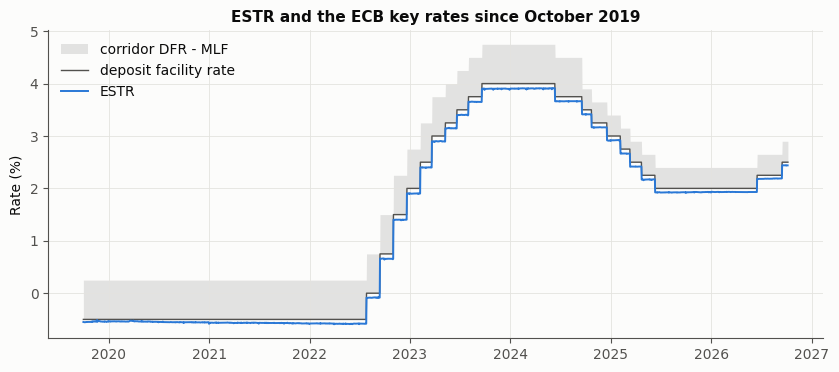

In [2]:
rates = key_rates.loc[estr.index[0]:]
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(rates.index, rates["DFR"], rates["MLF"], color=MUTED, alpha=0.15, lw=0, label="corridor DFR - MLF")
ax.plot(rates.index, rates["DFR"], color=MUTED, lw=1, label="deposit facility rate")
ax.plot(estr.index, 100 * estr, color=COLORS[0], lw=1.4, label="ESTR")
ax.set_ylabel("Rate (%)"); ax.set_title("ESTR and the ECB key rates since October 2019"); ax.legend(loc="upper left")
plt.show()

In [3]:
spread = 1e4 * (estr - key_rates["DFR"].reindex(estr.index) / 100)
by_year = spread.groupby(spread.index.year).agg(["mean", "std", "min", "max"])
by_year.columns = [f"ESTR - DFR {c} (bp)" for c in by_year.columns]
by_year["volume (EUR bn, mean)"] = fixings["VolumeMn"].groupby(fixings.index.year).mean() / 1e3
by_year["25-75 percentile range (bp, mean)"] = 100 * (fixings["R75"] - fixings["R25"]).groupby(fixings.index.year).mean()
by_year

,ESTR - DFR mean (bp),ESTR - DFR std (bp),ESTR - DFR min (bp),ESTR - DFR max (bp),"volume (EUR bn, mean)","25-75 percentile range (bp, mean)"
Date,,,,,,
2019,-4.24688,0.735704,-5.5,-1.1,31.0787,3.9375
2020,-4.66732,0.894832,-8.3,-2.2,41.2483,3.40467
2021,-6.77287,0.495702,-9,-5.8,46.0416,4.26744
2022,-8.57471,0.777631,-11,-7.2,56.0423,3.8249
2023,-9.96157,0.397152,-12,-9.3,60.9679,6.04706
2024,-8.94805,0.473696,-11.3,-8.1,52.9885,4.87891
2025,-7.78196,0.531441,-9.4,-6.6,63.2898,4.86667
2026,-6.66154,0.329648,-7.4,-5.8,65.3774,4.31795


The spread to the DFR is stable within a year (a standard deviation of about 1bp) and drifts slowly as excess liquidity
shrinks. This is what makes the **policy path** the backbone of the short end of the curve: between two meetings the
€STR is almost constant, and it jumps on the effective date of each decision.

### 1.2 Conventions

| Item | Convention |
|---|---|
| €STR accrual | ACT/360; a fixing applies from its business day to the next TARGET business day |
| Calendar | TARGET (New Year, Good Friday, Easter Monday, 1 May, 25-26 December) |
| OIS | fixed annual ACT/360 vs €STR compounded in arrears; spot start T+2; annual periods (short front stub), single period up to 1 year; payment 1 business day after each period end; modified following |
| ECB decisions | effective on the Wednesday after the meeting (start of the reserve maintenance period) |
| Model time | ACT/365 from the valuation date |

In [4]:
def roll(d, n=0, direction="forward"):
    return pd.Timestamp(np.busday_offset(np.datetime64(pd.Timestamp(d).date()), n, roll=direction, holidays=HOLIDAYS))

def modified_following(d):
    f = roll(d)
    return f if f.month == pd.Timestamp(d).month else roll(d, 0, "backward")

def add_tenor(d, tenor):
    n, unit = int(tenor[:-1]), tenor[-1]
    if unit == "W":
        return roll(d + pd.DateOffset(weeks=n))
    return modified_following(d + pd.DateOffset(months=n * (12 if unit == "Y" else 1)))

def time(d):
    # model time, ACT/365 from the valuation date (vectorised)
    if np.ndim(d) == 0:
        return (pd.Timestamp(d) - VALUATION).days / 365.0
    return np.asarray((pd.DatetimeIndex(d) - VALUATION).days, dtype=float) / 365.0

SPOT = roll(VALUATION, 2)
print(f"Spot date {SPOT.date()} ; 5Y maturity {add_tenor(SPOT, '5Y').date()}")

Spot date 2026-10-07 ; 5Y maturity 2031-10-07


## 2. From overnight fixings to term rates

A €STR leg pays the overnight fixings **compounded in arrears** over each period:
$$
R(T_1, T_2) = \frac{1}{\tau(T_1, T_2)}\left[\prod_{k}\left(1 + \frac{r_k\, n_k}{360}\right) - 1\right],
$$
where $r_k$ is the fixing of business day $k$ and $n_k$ the number of calendar days until the next business day. The ECB
publishes an index $I_t = 100\prod(1 + r_k n_k/360)$ and compounded averages over 1W to 12M. Rebuilding them from the
fixings checks the calendar and the day count.

In [5]:
days = np.array([(roll(d, 1) - d).days for d in estr.index])
index = 100 * np.concatenate([[1.0], np.cumprod(1 + estr.values * days / 360)])[:-1]
index = pd.Series(index, index=estr.index)
ecb_index = compounded["Index"].reindex(estr.index)

def compounded_average(d, months):
    start = d - pd.DateOffset(months=months)
    s = index.loc[:start].index[-1]
    return 100 * (index.loc[d] / index.loc[s] - 1) * 360 / (d - s).days

d = estr.index[-1]
pd.DataFrame({"rebuilt from fixings": [index.loc[d]] + [compounded_average(d, m) for m in (1, 3, 6, 12)],
              "ECB": [ecb_index.loc[d]] + [compounded["Avg" + t].loc[d] for t in ("1M", "3M", "6M", "12M")]},
             index=["index", "1M average (%)", "3M average (%)", "6M average (%)", "12M average (%)"]).assign(
    difference=lambda x: x.iloc[:, 0] - x.iloc[:, 1])

,rebuilt from fixings,ECB,difference
index,109.935,109.935,-5.30974e-10
1M average (%),2.34817,2.34817,4.1236e-06
3M average (%),2.24781,2.24781,3.00702e-06
6M average (%),2.12073,2.12073,-4.40688e-06
12M average (%),2.04256,2.04256,-3.8261e-07


In [6]:
print(f"Max index difference over {len(index)} days : {np.max(np.abs(index - ecb_index)):.2e}")

Max index difference over 1797 days : 5.00e-09


The rebuilt index matches the ECB to rounding (the ECB rounds the index to 8 decimals and the averages to 5): the TARGET
calendar and the ACT/360 day count are right. These backward-looking averages are realised rates; the curve is
about the **forward-looking** expectation of the same compounded rates, which is what OIS quotes give.

## 3. Instruments and quotes

### 3.1 Dated €STR OIS
For a spot-starting OIS with periods $[s_i, e_i]$ paid at $p_i$, the floating leg of period $i$ is worth
$P(0,p_i)\,(P(0,s_i)/P(0,e_i) - 1)$ (single curve, payment lag kept), so the par rate is
$$
K = \frac{\sum_i P(0,p_i)\left(P(0,s_i)/P(0,e_i) - 1\right)}{\sum_i \tau_i\, P(0,p_i)}, \qquad \tau_i = \frac{e_i - s_i}{360}.
$$
The instrument plugs into the existing `Bootstrapper` through the `Instrument` interface (`implied_quote(curve)`).

In [7]:
class OIS(Instrument):
    # Spot-starting ESTR OIS with a dated schedule ; maturity (pillar) = last payment time
    kind = "ESTR OIS"

    def __init__(self, tenor, rate, spot=SPOT, pay_lag=1):
        self.tenor = tenor
        end = add_tenor(spot, tenor)
        n, unit = int(tenor[:-1]), tenor[-1]
        months = n * (12 if unit == "Y" else 1) if unit != "W" else 0
        ends = [end]
        k = 12
        while months - k > 0:                                   # annual periods, short front stub
            ends.insert(0, modified_following(spot + pd.DateOffset(months=months - k)))
            k += 12
        starts = [spot] + ends[:-1]
        pays = [roll(e, pay_lag) for e in ends]
        self.dates = pd.DataFrame({"start": starts, "end": ends, "payment": pays})
        self.t_start, self.t_end, self.t_pay = time(starts), time(ends), time(pays)
        self.accrual = np.array([(e - s).days / 360 for s, e in zip(starts, ends)])
        super().__init__(self.t_pay[-1], rate)

    def implied_quote(self, curve):
        P_pay = curve.discount(self.t_pay)
        floating = np.sum(P_pay * (curve.discount(self.t_start) / curve.discount(self.t_end) - 1))
        return floating / np.sum(self.accrual * P_pay)

    def __repr__(self):
        return f"OIS({self.tenor}, {100 * self.quote:.4f}%)"

TENORS = ["1W", "2W", "1M", "2M", "3M", "4M", "5M", "6M", "9M", "1Y", "18M", "2Y", "3Y", "4Y", "5Y", "6Y", "7Y", "8Y",
          "9Y", "10Y", "12Y", "15Y", "20Y", "25Y", "30Y"]
OIS("18M", 0.0).dates

,start,end,payment
0,2026-10-07,2027-04-07,2027-04-08
1,2027-04-07,2028-04-07,2028-04-10


### 3.2 Quotes: hand-filled file, or proxy from the AAA curve
The notebook first looks for the most recent filled `ESTR_OIS_Quotes_YYYYMMDD.csv`. Without one, it builds **proxy**
quotes from the ECB **AAA government curve**, which is published with its Svensson parameters:
$$
z(T) = \beta_0 + \beta_1 \frac{1 - e^{-T/\tau_1}}{T/\tau_1} + \beta_2\left[\frac{1 - e^{-T/\tau_1}}{T/\tau_1} - e^{-T/\tau_1}\right] + \beta_3\left[\frac{1 - e^{-T/\tau_2}}{T/\tau_2} - e^{-T/\tau_2}\right].
$$

In [8]:
TENOR_YEARS = {c[3:]: (int(c[3:-1]) / 12 if c.endswith("M") else int(c[3:-1])) for c in aaa.columns if c.startswith("SR_")}
SVENSSON = ["BETA0", "BETA1", "BETA2", "BETA3", "TAU1", "TAU2"]

def svensson(T, b0, b1, b2, b3, t1, t2):
    x1, x2 = np.asarray(T) / t1, np.asarray(T) / t2
    l1 = (1 - np.exp(-x1)) / x1
    return b0 + b1 * l1 + b2 * (l1 - np.exp(-x1)) + b3 * ((1 - np.exp(-x2)) / x2 - np.exp(-x2))

row = aaa.loc[VALUATION]
T = np.array(list(TENOR_YEARS.values()))
check = pd.DataFrame({"ECB spot rate (%)": row[[f"SR_{k}" for k in TENOR_YEARS]].values,
                      "Svensson formula (%)": svensson(T, *row[SVENSSON])}, index=list(TENOR_YEARS))
print(f"max difference : {1e4 * np.max(np.abs(check.iloc[:, 0] - check.iloc[:, 1])) / 100:.1e} bp")
check.T

max difference : 9.0e-09 bp


,3M,6M,9M,1Y,2Y,3Y,4Y,5Y,6Y,7Y,8Y,9Y,10Y,12Y,15Y,20Y,25Y,30Y
ECB spot rate (%),2.53048,2.67429,2.77803,2.85274,2.99713,3.05553,3.10718,3.16745,3.23488,3.30512,3.37451,3.44062,3.50198,3.60791,3.72367,3.81782,3.82287,3.7722
Svensson formula (%),2.53048,2.67429,2.77803,2.85274,2.99713,3.05553,3.10718,3.16745,3.23488,3.30512,3.37451,3.44062,3.50198,3.60791,3.72367,3.81782,3.82287,3.7722


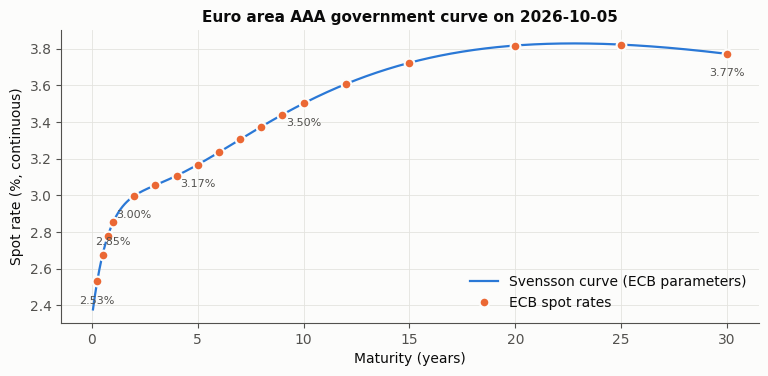

In [9]:
grid = np.linspace(0.05, 30, 600)
last = aaa.index[-1]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(grid, svensson(grid, *aaa.loc[last, SVENSSON]), lw=1.6, color=COLORS[0], label="Svensson curve (ECB parameters)")
ax.plot(T, aaa.loc[last, [f"SR_{k}" for k in TENOR_YEARS]].values, "o", ms=7, color=COLORS[1],
        markeredgecolor=SURFACE, markeredgewidth=1.5, label="ECB spot rates")
for k in ["3M", "1Y", "2Y", "5Y", "10Y", "30Y"]:
    ax.annotate(f"{aaa.loc[last, 'SR_' + k]:.2f}%", (TENOR_YEARS[k], aaa.loc[last, "SR_" + k]), textcoords="offset points",
                xytext=(0, -16), ha="center", fontsize=8, color=MUTED)
ax.set_xlabel("Maturity (years)"); ax.set_ylabel("Spot rate (%, continuous)")
ax.set_title(f"Euro area AAA government curve on {last.date()}"); ax.legend(loc="lower right"); plt.show()

**Government vs OIS basis.** AAA bonds and €STR OIS do not yield the same: bonds carry a liquidity / supply premium and
the 3-month point of the Svensson fit is an extrapolation (no AAA bond is that short). The basis is measured ex post:
the AAA 3-month rate on date $t$ minus the €STR **actually compounded** over the next 3 months (from the ECB index).

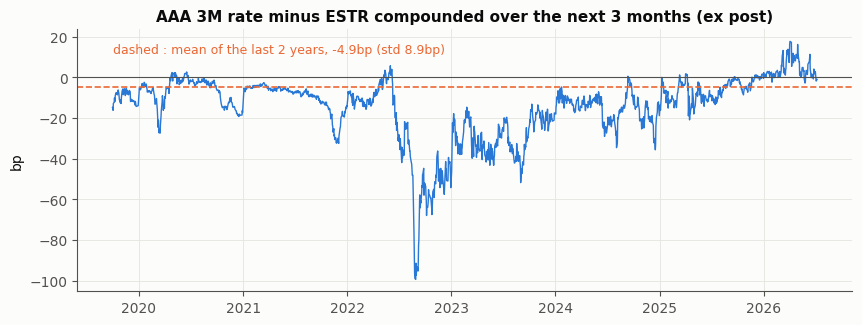

In [10]:
log_index = np.log(compounded["Index"])
rows = []
for d in aaa.index:
    e = d + pd.DateOffset(months=3)
    if e > log_index.index[-1]:
        break
    d0, d1 = log_index.loc[:d].index[-1], log_index.loc[:e].index[-1]
    realised = (log_index.loc[d1] - log_index.loc[d0]) / ((d1 - d0).days / 365)
    rows.append((d, 1e2 * (aaa.loc[d, "SR_3M"] / 100 - realised) * 100))
basis = pd.Series(dict(rows))
window = basis.loc[VALUATION - pd.DateOffset(years=2):]
BASIS_BP, BASIS_STD = float(window.mean()), float(window.std())
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(basis.index, basis, lw=1, color=COLORS[0])
ax.axhline(0, color=MUTED, lw=0.8); ax.axhline(BASIS_BP, color=COLORS[1], lw=1.2, ls="--")
ax.text(basis.index[0], 12, f"dashed : mean of the last 2 years, {BASIS_BP:+.1f}bp (std {BASIS_STD:.1f}bp)", color=COLORS[1], fontsize=9)
ax.set_ylabel("bp"); ax.set_title("AAA 3M rate minus ESTR compounded over the next 3 months (ex post)"); plt.show()

The basis is far from stable: a few bp below zero in calm periods, down to −100bp in 2022 when the ECB hiked faster
than the market expected (ex post, the realised €STR includes the policy surprises, so this measure mixes the
government - OIS basis with forecast errors). It is the main uncertainty of the proxy.

**Proxy instantaneous forward curve.** €STR flat at today's fixing until the next ECB effective date (no decision
can change it before), then the AAA instantaneous forward minus the average basis of the last two years. Proxy OIS
quotes are the par rates of this curve. With real quotes, this step disappears.

In [11]:
def latest_quote_file():
    files = sorted(glob.glob(os.path.join(DATA, "ESTR_OIS_Quotes_[0-9]*.csv")))
    for f in reversed(files):
        q = pd.read_csv(f).dropna(subset=["Rate"])
        if len(q):
            return f, q
    return None, None

upcoming = meetings.loc[(meetings["Status"] == "upcoming") & (meetings["Effective"] > VALUATION)].reset_index(drop=True)
FIRST_EFFECTIVE = time(upcoming["Effective"].iloc[0])
ON = np.log1p(estr.loc[VALUATION] / 360) * 365               # overnight ESTR, continuously compounded (ACT/365)

def proxy_curve(basis_bp=BASIS_BP):
    grid = np.unique(np.concatenate([[FIRST_EFFECTIVE], np.linspace(FIRST_EFFECTIVE, 32, 600)]))
    h = 1e-4
    aaa_y = lambda t: svensson(t, *row[SVENSSON]) / 100 * t
    fwd = (aaa_y(grid + h) - aaa_y(grid - h)) / (2 * h) - basis_bp * 1e-4
    y = ON * FIRST_EFFECTIVE + np.concatenate([[0.0], np.cumsum(0.5 * (fwd[1:] + fwd[:-1]) * np.diff(grid))])
    return YieldCurve(grid, y / grid, "linear_zero", name=f"proxy (AAA {-basis_bp:+.1f}bp)")

quote_file, quote_table = latest_quote_file()
if quote_file:
    SOURCE = f"market quotes from {os.path.basename(quote_file)}"
    quotes = [OIS(t, r / 100) for t, r in zip(quote_table["Tenor"], quote_table["Rate"])]
else:
    SOURCE = "PROXY quotes (AAA curve, see 3.2)"
    proxy = proxy_curve()
    quotes = [OIS(t, 0.0) for t in TENORS]
    for q in quotes:
        q.quote = q.implied_quote(proxy)
print("Quote source :", SOURCE)
pd.DataFrame({"tenor": [q.tenor for q in quotes], "end": [q.dates["end"].iloc[-1].date() for q in quotes],
              "periods": [len(q.dates) for q in quotes], "par rate (%)": [100 * q.quote for q in quotes]}).set_index("tenor").T

Quote source : PROXY quotes (AAA curve, see 3.2)


tenor,1W,2W,1M,2M,3M,4M,5M,6M,9M,1Y,...,6Y,7Y,8Y,9Y,10Y,12Y,15Y,20Y,25Y,30Y
end,2026-10-14,2026-10-21,2026-11-09,2026-12-07,2027-01-07,2027-02-08,2027-03-08,2027-04-07,2027-07-07,2027-10-07,...,2032-10-07,2033-10-07,2034-10-09,2035-10-08,2036-10-07,2038-10-07,2041-10-07,2046-10-08,2051-10-09,2056-10-09
periods,1,1,1,1,1,1,1,1,1,1,...,6,7,8,9,10,12,15,20,25,30
par rate (%),2.4385,2.43907,2.45024,2.50572,2.56536,2.62215,2.66728,2.71179,2.82351,2.90902,...,3.28217,3.34808,3.41268,3.47281,3.52807,3.6218,3.72205,3.80457,3.81912,3.79664


## 4. Standard bootstrap (baseline and validation)

One pillar per OIS at its last payment date, solved by the existing `Bootstrapper` (sequential for raw, simultaneous for
monotone convex). This is **not the final curve**, but it is needed for three reasons:
1. **Validation** : it is the first time the dated `OIS` class (TARGET calendar, T+2, ACT/360, payment lag, front stub)
   goes through the bootstrap. Exact repricing checks the whole chain instruments → bootstrap → curve, which the
   meeting-step curve of Section 5 cannot do since it does not reprice the short quotes exactly.
2. **Long end** : beyond the last ECB meeting node, the curve of Section 5 adds one pillar per OIS with a flat forward,
   which is exactly the raw bootstrap of this section.
3. **Motivation and benchmark** : standard interpolations put the forward jumps at the OIS maturities, or spread them,
   which shows why the short end needs the ECB dates (Section 5) and measures what that choice changes.

The comparison of interpolation methods themselves (locality, smoothness, linearity) is done in `yield_curve.ipynb`;
only raw (flat forwards, linear, used for risk) and monotone convex (smooth market standard) are kept here.

In [12]:
METHODS = ["raw", "monotone_convex"]
curves, reports = {}, {}
for m in METHODS:
    boot = Bootstrapper(quotes, method=m)
    curves[m] = boot.run()
    reports[m] = boot
pd.DataFrame({m: {"max residual (bp)": b.max_residual_bp, "solver": b.solver, "time (ms)": 1e3 * b.elapsed}
              for m, b in reports.items()}).T

,max residual (bp),solver,time (ms)
raw,1.07553e-12,sequential,36.041
monotone_convex,6.56614e-09,simultaneous (hybr),"4,235.58"


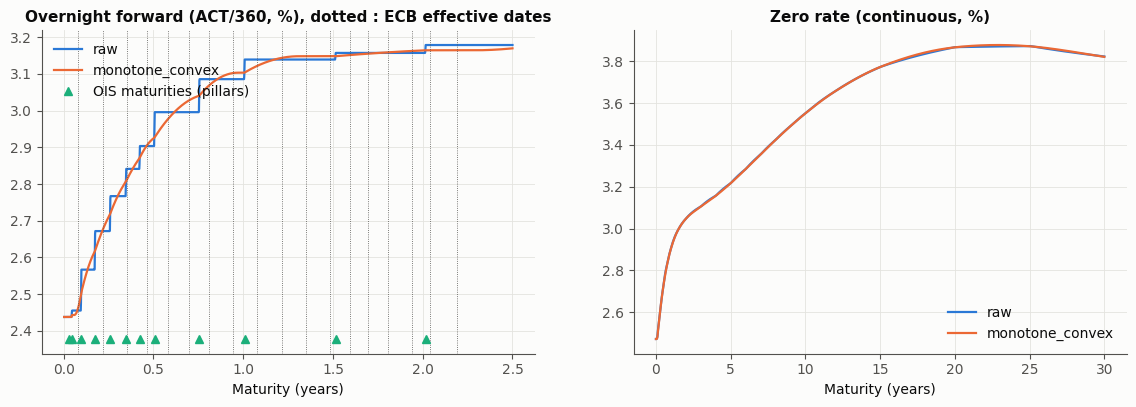

In [13]:
# overnight forward : simple ACT/360 rate over one calendar day (model time is ACT/365, hence 360/365)
on_fwd = lambda c, t: 100 * c.forward_rate(t, t + 1 / 365, "simple") * 360 / 365
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
t_short, t_long = np.linspace(1 / 365, 2.5, 2000), np.linspace(1 / 365, 30, 3000)
for k, m in enumerate(METHODS):
    axes[0].plot(t_short, on_fwd(curves[m], t_short), lw=1.6, label=m, color=COLORS[k])
    axes[1].plot(t_long, 100 * curves[m].zero_rate(t_long), lw=1.6, label=m, color=COLORS[k])
for e in upcoming["Effective"]:
    if time(e) <= 2.5:
        axes[0].axvline(time(e), color=MUTED, lw=0.6, ls=":")
axes[0].plot([q.maturity for q in quotes if q.maturity <= 2.5], [100 * estr.loc[VALUATION] - 0.06] * sum(q.maturity <= 2.5 for q in quotes),
             "^", ms=6, color=COLORS[2], label="OIS maturities (pillars)")
axes[0].set_title("Overnight forward (ACT/360, %), dotted : ECB effective dates")
axes[1].set_title("Zero rate (continuous, %)")
axes[0].legend(loc="upper left"); axes[1].legend(loc="lower right")
for ax in axes:
    ax.set_xlabel("Maturity (years)")
plt.show()

Both curves reprice every quote (residuals below $10^{-8}$ bp), which validates the `OIS` instrument and the conventions.
On the zero rates they are indistinguishable, but the overnight forwards show the problem of the short end:
- **raw** jumps at the OIS maturities (triangles), dates on which nothing happens to the €STR ;
- **monotone convex** moves continuously and spreads each ECB decision over several months.

Neither reflects how the €STR actually moves: in steps, on the ECB effective dates (dotted lines). Section 5 keeps this
raw bootstrap for the long end and replaces the short end by steps on these dates.

## 5. The short end on ECB meeting dates

**Construction.** Up to two years, the instantaneous forward is a step function with jumps on the effective dates
$E_1 < E_2 < \dots$: $f(t) = r_{ON}$ on $[0, E_1)$ (today's €STR, known until the next decision) and $f_k$ on
$[E_k, E_{k+1})$. The levels $f_k$ are fitted to the OIS quotes that mature before the last date, with a small penalty
on the jumps ($\lambda\,(f_k - f_{k-1})$ added to the least-squares residuals, i.e. $\lambda^2 (f_k - f_{k-1})^2$ in the objective, $\lambda = 0.002$) because there are more meetings than quotes: the quotes
are repriced to a fraction of a basis point and the remaining freedom keeps the path smooth. Beyond, each remaining OIS adds
one pillar with a flat forward (raw interpolation), solved sequentially. The whole curve is a single `YieldCurve` with
raw interpolation on the pillars (effective dates, then OIS maturities).

In [14]:
def meeting_curve(quotes, effective_times, horizon=2.0, penalty=0.002):
    nodes = np.array([e for e in effective_times if e <= horizon])        # E_1 < ... < E_n
    short = [q for q in quotes if q.maturity <= nodes[-1]]
    long = [q for q in quotes if q.maturity > nodes[-1]]

    def build(levels):
        # forward ON on [0, E_1), levels[k] on [E_{k+1}, E_{k+2}) : y(E_k) = int_0^{E_k} f, raw interpolation
        y = ON * nodes[0] + np.concatenate([[0.0], np.cumsum(levels * np.diff(nodes))])
        return YieldCurve(nodes, y / nodes, "raw"), y

    def residuals(levels):
        c, _ = build(levels)
        fit = [1e4 * q.residual(c) for q in short]
        jumps = penalty * 1e4 * np.diff(np.concatenate([[ON], levels]))
        return np.concatenate([fit, jumps])

    sol = least_squares(residuals, np.full(len(nodes) - 1, ON))
    _, y = build(sol.x)
    times, zeros = list(nodes), list(y / nodes)
    for q in long:                                            # long end : one pillar per OIS, flat forward
        def f(z):
            return q.residual(YieldCurve(np.array(times + [q.maturity]), np.array(zeros + [z]), "raw"))
        zeros.append(brentq(f, -0.05, 0.2, xtol=1e-14)); times.append(q.maturity)
    curve = YieldCurve(np.array(times), np.array(zeros), "raw", name="ESTR, ECB meeting steps")
    levels = pd.Series(sol.x, index=nodes[:-1])               # forward from each effective date to the next one
    return curve, levels, short

effective_times = time(upcoming["Effective"])
step, levels, short = meeting_curve(quotes, effective_times)
print(f"{len(levels)} meeting steps fitted on {len(short)} short OIS")
pd.Series({q.tenor: 1e4 * q.residual(step) for q in quotes}, name="residual (bp)").to_frame().T

15 meeting steps fitted on 11 short OIS


,1W,2W,1M,2M,3M,4M,5M,6M,9M,1Y,...,6Y,7Y,8Y,9Y,10Y,12Y,15Y,20Y,25Y,30Y
residual (bp),0,0,0.785277,-0.0347331,-0.274677,0.117204,0.00120478,-0.000819347,0.000145618,-6.21809e-05,...,-1.38778e-13,-5.55112e-13,-6.93889e-14,7.28584e-12,0,2.08167e-13,-6.93889e-14,1.05471e-11,-4.44089e-12,-7.07767e-12


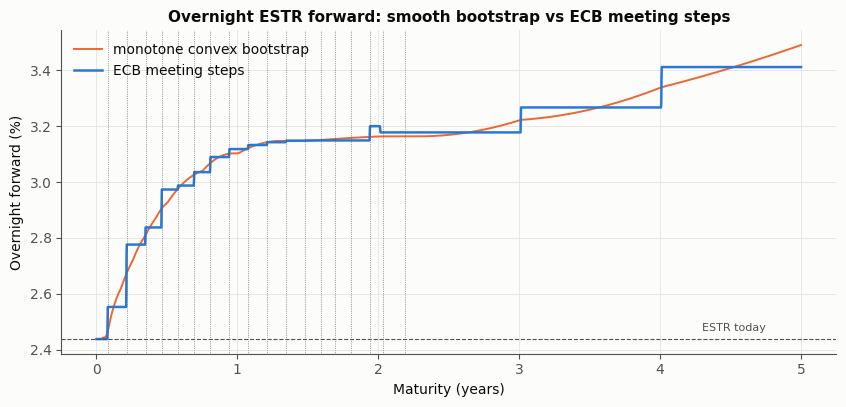

In [15]:
t = np.linspace(1 / 365, 5, 3000)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(t, on_fwd(curves["monotone_convex"], t), lw=1.4, color=COLORS[1], label="monotone convex bootstrap")
ax.plot(t, on_fwd(step, t), lw=1.8, color=COLORS[0], label="ECB meeting steps")
ax.axhline(100 * estr.loc[VALUATION], color=MUTED, lw=0.8, ls="--")
ax.text(4.3, 100 * estr.loc[VALUATION] + 0.03, "ESTR today", color=MUTED, fontsize=8)
for e in effective_times:
    ax.axvline(e, color=MUTED, lw=0.5, ls=":")
ax.set_xlabel("Maturity (years)"); ax.set_ylabel("Overnight forward (%)"); ax.legend(loc="upper left")
ax.set_title("Overnight ESTR forward: smooth bootstrap vs ECB meeting steps"); plt.show()

The long quotes are repriced exactly. The short ones are not quite (up to about 0.8bp on 1M): the 1M and 2M OIS both end
between the first two effective dates, so one step level has to fit two quotes. With **proxy** quotes generated from a
smooth curve this cannot be exact; with market quotes, which already price a step path, the residuals are much smaller,
and the remaining ones measure turn-of-month / turn-of-year effects that a richer curve would add as extra steps.

### 5.1 What changes with respect to Section 4
Same quotes, almost the same discount factors: the constructions only differ by **where the overnight forward changes
level**. The table reads the overnight forward on a few dates around the first two ECB effective dates, then compares
the curves on discounting and on a forward between two meetings.

In [16]:
E1, E2 = upcoming["Effective"].iloc[0], upcoming["Effective"].iloc[1]
dates = [VALUATION + pd.Timedelta(days=15), E1 - pd.Timedelta(days=1), E1 + pd.Timedelta(days=2),
         quotes[TENORS.index("1M")].dates["payment"].iloc[-1] + pd.Timedelta(days=2),
         quotes[TENORS.index("2M")].dates["payment"].iloc[-1] + pd.Timedelta(days=2), E2 + pd.Timedelta(days=5)]
built = {"raw (Section 4)": curves["raw"], "monotone convex (Section 4)": curves["monotone_convex"], "meeting steps (Section 5)": step}
table = pd.DataFrame({name: [on_fwd(c, time(d)) for d in dates] for name, c in built.items()},
                     index=[d.date() for d in dates])
table.index.name = "overnight forward (%) on"
display(table.round(3))

g = np.linspace(0.01, 2, 2000)
summary = pd.DataFrame({name: {
    "max |zero - steps| on 0-2y (bp)": 1e4 * np.max(np.abs(c.zero_rate(g) - step.zero_rate(g))),
    "max |DF - steps| on 0-2y": np.max(np.abs(c.discount(g) - step.discount(g))),
    f"forward {E1.date()} -> {E2.date()} (%)": 100 * c.forward_rate(time(E1), time(E2), "simple") * 360 / 365}
    for name, c in built.items()}).T
summary

,raw (Section 4),monotone convex (Section 4),meeting steps (Section 5)
overnight forward (%) on,,,
2026-10-20,2.438,2.438,2.438
2026-11-03,2.456,2.46,2.438
2026-11-06,2.456,2.476,2.553
2026-11-12,2.567,2.516,2.553
2026-12-10,2.672,2.627,2.553
2026-12-28,2.672,2.69,2.776


,max |zero - steps| on 0-2y (bp),max |DF - steps| on 0-2y,forward 2026-11-04 -> 2026-12-23 (%)
raw (Section 4),2.31756,4.97993e-05,2.58981
monotone convex (Section 4),1.87049,4.01929e-05,2.58489
meeting steps (Section 5),0,0,2.55724


Up to the first ECB effective date the €STR cannot change: the meeting steps keep today's fixing, while raw and
monotone convex already drift up. After it, the steps jump once and stay flat until the next decision, whereas raw jumps
at the 1M and 2M payment dates. Discounting is barely affected (about 2bp on zero rates, $5\times10^{-5}$ on discount
factors up to two years), but the forward between the two first meetings differs by about 3bp with the same quotes:
the construction matters for forward-starting instruments and for reading the policy path, not for plain discounting.

### 5.2 Implied policy path
Each step is the €STR expected after a decision. Subtracting the current €STR - DFR spread gives the implied deposit
facility rate, and the change since today in units of 25bp moves. With **proxy quotes** this is the path implied by
AAA bonds, not by the OIS market.

In [17]:
current_spread = float(spread.iloc[-63:].mean()) * 1e-4
simple = lambda f: (np.exp(f / 365) - 1) * 360                # continuous ACT/365 forward -> overnight ACT/360
path = pd.DataFrame({"decision": upcoming["Decision"].dt.date.iloc[:len(levels)].values,
                     "effective": upcoming["Effective"].dt.date.iloc[:len(levels)].values,
                     "ESTR forward (%)": 100 * simple(levels.values)})
path["implied DFR (%)"] = path["ESTR forward (%)"] - 100 * current_spread
path["change vs today (bp)"] = 1e4 * (simple(levels.values) - estr.loc[VALUATION])
path["cumulative 25bp moves"] = path["change vs today (bp)"] / 25
print(f"DFR today {key_rates['DFR'].loc[VALUATION]:.2f}% ; ESTR - DFR spread (last 3 months) {1e4 * current_spread:+.1f}bp ; source : {SOURCE}")
path

DFR today 2.50% ; ESTR - DFR spread (last 3 months) -6.3bp ; source : PROXY quotes (AAA curve, see 3.2)


,decision,effective,ESTR forward (%),implied DFR (%),change vs today (bp),cumulative 25bp moves
0,2026-10-29,2026-11-04,2.55289,2.61559,11.4889,0.459555
1,2026-12-17,2026-12-23,2.77633,2.83903,33.8334,1.35334
2,2027-02-04,2027-02-10,2.83773,2.90043,39.9734,1.59894
3,2027-03-18,2027-03-24,2.97358,3.03627,53.5575,2.1423
4,2027-04-29,2027-05-05,2.98781,3.05051,54.9814,2.19926
5,2027-06-10,2027-06-16,3.03587,3.09856,59.7865,2.39146
6,2027-07-22,2027-07-28,3.0899,3.1526,65.19,2.6076
7,2027-09-09,2027-09-15,3.11845,3.18115,68.0452,2.72181
8,2027-10-28,2027-11-03,3.13304,3.19574,69.5038,2.78015
9,2027-12-16,2027-12-22,3.14304,3.20574,70.5043,2.82017


### 5.3 How much does the proxy assumption matter?
The proxy depends on the AAA - OIS basis. Shifting it by one standard deviation moves every quote, the implied path and
the swap rates by the same amount, a reminder that **real quotes are needed** before reading anything into the levels.

In [18]:
rows = {}
for name, b in {"basis - 1 std": BASIS_BP - BASIS_STD, "basis (2y mean)": BASIS_BP, "basis + 1 std": BASIS_BP + BASIS_STD, "no basis": 0.0}.items():
    pc = proxy_curve(b)
    qs = [OIS(t, 0.0) for t in TENORS]
    for q in qs:
        q.quote = q.implied_quote(pc)
    _, lv, _ = meeting_curve(qs, effective_times)
    rows[f"{name} ({b:+.1f}bp)"] = {"2Y OIS (%)": 100 * qs[TENORS.index("2Y")].quote, "5Y OIS (%)": 100 * qs[TENORS.index("5Y")].quote,
                                   "10Y OIS (%)": 100 * qs[TENORS.index("10Y")].quote,
                                   "25bp moves priced in 1 year": (simple(lv.values[np.searchsorted(lv.index, 1.0) - 1]) - estr.loc[VALUATION]) / 0.0025}
pd.DataFrame(rows).T

,2Y OIS (%),5Y OIS (%),10Y OIS (%),25bp moves priced in 1 year
basis - 1 std (-13.8bp),3.13876,3.30647,3.61698,3.07375
basis (2y mean) (-4.9bp),3.05206,3.21776,3.52807,2.72181
basis + 1 std (+4.0bp),2.96544,3.12913,3.43924,2.36987
no basis (+0.0bp),3.00401,3.16859,3.4788,2.52661


## 6. Risk: par-point sensitivities

Each quote is bumped by +1bp, the curve rebuilt and the instrument repriced. The instrument is an **18m × 4y forward
starting receiver OIS** (receive fixed 3%, notional EUR 10m), whose cash flows lie between the pillars. The meeting-step
curve concentrates the risk on the quotes that bracket the flows; the smooth curve spreads it.

In [19]:
class ForwardOIS(OIS):
    # receiver OIS starting at `start` (tenor from spot) for `tenor`, fixed rate K ; value per unit notional
    def __init__(self, start, tenor, K):
        super().__init__(tenor, K, spot=add_tenor(SPOT, start))

    def value(self, curve):
        P_pay = curve.discount(self.t_pay)
        floating = np.sum(P_pay * (curve.discount(self.t_start) / curve.discount(self.t_end) - 1))
        return self.quote * np.sum(self.accrual * P_pay) - floating

trade, NOTIONAL = ForwardOIS("18M", "4Y", 0.03), 10_000_000

def rebuild(qs, method):
    return meeting_curve(qs, effective_times)[0] if method == "meeting steps" else Bootstrapper(qs, method=method).run()

risk = {}
for method in ["meeting steps", "monotone_convex", "raw"]:
    base = trade.value(rebuild(quotes, method))
    row_ = {}
    for i, q in enumerate(quotes):
        bumped = [OIS(x.tenor, x.quote + (1e-4 if j == i else 0.0)) for j, x in enumerate(quotes)]
        row_[q.tenor] = NOTIONAL * (trade.value(rebuild(bumped, method)) - base)
    risk[method] = row_
    parallel = NOTIONAL * (trade.value(rebuild([OIS(x.tenor, x.quote + 1e-4) for x in quotes], method)) - base)
    risk[method]["sum of par points"] = sum(row_.values())
    risk[method]["parallel +1bp on all quotes"] = parallel
risk = pd.DataFrame(risk)
print(f"Value {NOTIONAL * base:,.0f} EUR")
risk[(risk.abs() > 1).any(axis=1)].round(0)

Value -127,475 EUR


,meeting steps,monotone_convex,raw
6M,-8,-7,-7
1Y,30,31,31
18M,"1,429","1,436","1,427"
2Y,33,15,34
3Y,6,-12,6
4Y,14,225,14
5Y,"-2,270","-2,794","-2,270"
6Y,"-2,762","-3,940","-2,762"
7Y,0,403,0
8Y,0,2,0


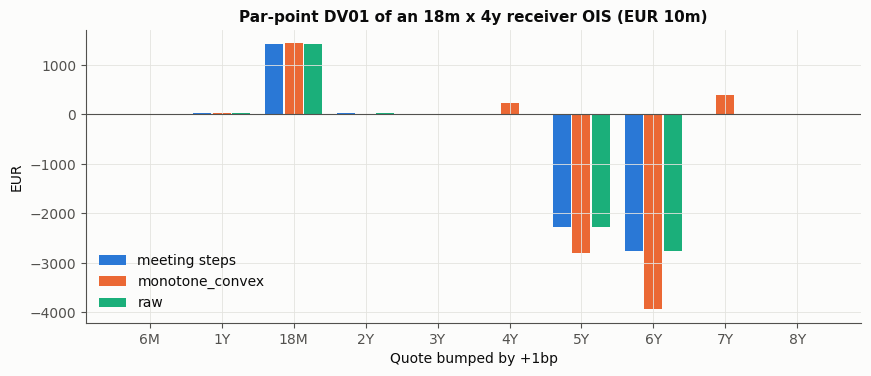

In [20]:
shown = risk.drop(["sum of par points", "parallel +1bp on all quotes"])
shown = shown[(shown.abs() > 1).any(axis=1)]
x = np.arange(len(shown))
fig, ax = plt.subplots(figsize=(10, 3.8))
for k, m in enumerate(shown.columns):
    ax.bar(x + (k - 1) * 0.27, shown[m], width=0.25, label=m, color=COLORS[k])
ax.set_xticks(x); ax.set_xticklabels(shown.index); ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xlabel("Quote bumped by +1bp"); ax.set_ylabel("EUR"); ax.set_title("Par-point DV01 of an 18m x 4y receiver OIS (EUR 10m)")
ax.legend(); plt.show()

- **Meeting steps and raw** give the same par-point risk here: both have flat forwards between their pillars, and the
  flows of the trade start after the last meeting node (18 months), where both curves are built the same way. The risk
  sits on the quotes that bracket the flows (18M, 5Y, 6Y).
- **Monotone convex** has the same parallel DV01 but a different split, with sensitivities to the 4Y and 7Y quotes and
  a **sum of par-point DV01s far from the parallel DV01**: the method is not linear in the quotes (its forward
  constraints switch on and off), so its bucketed risk is not additive. This is a practical argument for flat forwards
  on a risk curve, on top of the monetary policy argument of Section 5.

## 7. Conclusions and limitations

- The **conventions are validated**: the ECB €STR index and compounded averages are rebuilt exactly from the fixings
  (TARGET calendar, ACT/360), and the Svensson formula reproduces the ECB AAA curve to machine precision.
- Every interpolation reprices the OIS exactly, but only the **meeting-step** construction gives an overnight forward
  that moves like the €STR (flat between decisions, jumps on effective dates) and a readable policy path.
- **Proxy quotes**: without €STR OIS quotes, the levels come from the AAA government curve and an ex-post basis that
  has swung by tens of basis points since 2019. Fill `Data/EUR/ESTR_OIS_Quotes_YYYYMMDD.csv` to build the market curve.
- Not modelled yet: turn-of-year effects, the €STR - DFR spread drift, convexity of €STR futures (if they are used as
  quotes), and the long end beyond the last quote (flat forward).

## 8. Next step: the `EstrCurveBuilder` class

The class will gather the code of this notebook:

| Piece | Content |
|---|---|
| `TargetCalendar` | business days, modified following, tenor arithmetic, spot date |
| `EstrIndex` | €STR fixings, compounded index and averages, realised compounded rate over any period |
| `OIS`, `ForwardOIS` (and `Deposit`, `MeetingOIS`) | dated instruments with `implied_quote(curve)` and `value(curve)` |
| `QuoteSource` | hand-filled quote files, proxy from the AAA curve (with its basis) |
| `EstrCurveBuilder` | `build(method="meeting_steps" or an interpolation)`, `reprice()`, `policy_path()`, `par_point_risk(instrument)`, `history(dates)` to rebuild a curve every day |

It will return the existing `YieldCurve`, so the €STR curve can be used directly by the pricers (`RatePricer`,
`HullWhite`) of the other notebooks.